# Initial Exploratory Data Analysis

## Project: Predicting Successful NFL Third Down Conversions

This project examines NFLverse play-by-play data from the 2023-2026 seasons. The goal is to identify pre-play factors associated with successful third down conversions, including yards to go, field position, quarter, score differential, play type, formation and time remaining.

**Data Source:** [NFLverse Play-by-Play Data](https://github.com/nflverse/nflverse-data/releases/tag/pbp)

## 1. Data Loading and Initial Review

In [65]:
# Importing Libraries
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Locating and setting the data folder
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

data_dir = project_root / "data" / "raw"

# Loading the data and creating the combined DataFrame
pbp_2023 = pd.read_csv(data_dir / "play_by_play_2023.csv", low_memory=False)
pbp_2024 = pd.read_csv(data_dir / "play_by_play_2024.csv", low_memory=False)
pbp_2025 = pd.read_csv(data_dir / "play_by_play_2025.csv", low_memory=False)
pbp_2026 = pd.read_csv(data_dir / "play_by_play_2026.csv", low_memory=False)

pbp = pd.concat([pbp_2023, pbp_2024, pbp_2025, pbp_2026], ignore_index=True)

pbp.head(5)


,play_id,game_id,old_game_id,home_team,away_team,season_type,week,posteam,posteam_type,defteam,...,out_of_bounds,home_opening_kickoff,qb_epa,xyac_epa,xyac_mean_yardage,xyac_median_yardage,xyac_success,xyac_fd,xpass,pass_oe
0,1,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,NaN,NaN,NaN,...,0,1,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,39,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,WAS,home,ARI,...,0,1,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,55,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,WAS,home,ARI,...,0,1,-0.336103,NaN,NaN,NaN,NaN,NaN,0.515058,-51.505846
3,77,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,WAS,home,ARI,...,0,1,0.703308,0.340652,3.328642,1.0,0.996628,0.583928,0.661106,33.889407
4,102,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,WAS,home,ARI,...,0,1,0.469799,NaN,NaN,NaN,NaN,NaN,0.196065,-19.606467


In [66]:
print(f"Total: {pbp.shape[0]:,} rows, {pbp.shape[1]:,} columns\n")
print(f"Dataset: {pbp.shape[0]:,} plays from 2023-2026 seasons\n")
pbp["season"].value_counts().sort_index()

Total: 156,084 rows, 372 columns

Dataset: 156,084 plays from 2023-2026 seasons



season
2023    49665
2024    49492
2025    48771
2026     8156
Name: count, dtype: int64

## 2. Reviewing the Complete Dataset

In [67]:
pbp.info()

<class 'pandas.DataFrame'>
RangeIndex: 156084 entries, 0 to 156083
Columns: 372 entries, play_id to pass_oe
dtypes: float64(181), int64(39), object(16), str(136)
memory usage: 531.7+ MB


In [68]:
pbp.describe()

,play_id,old_game_id,week,yardline_100,quarter_seconds_remaining,half_seconds_remaining,game_seconds_remaining,quarter_end,drive,sp,...,out_of_bounds,home_opening_kickoff,qb_epa,xyac_epa,xyac_mean_yardage,xyac_median_yardage,xyac_success,xyac_fd,xpass,pass_oe
count,156084.000000,1.560840e+05,156084.000000,144945.000000,156067.000000,156067.000000,156067.000000,156084.000000,154292.000000,156084.000000,...,156084.000000,156084.000000,154280.000000,52770.000000,52770.000000,52770.000000,52770.000000,52770.000000,118896.000000,115501.000000
mean,2186.581008,2.024291e+09,9.537070,47.756487,408.920278,803.135583,1704.052497,0.017651,11.318098,0.075447,...,0.085922,0.507547,0.006451,0.733447,5.527103,3.702274,0.775842,0.578875,0.628758,-1.418037
std,1274.076580,9.383605e+05,5.736511,23.932132,282.995402,560.986725,1058.225076,0.131679,6.591909,0.264111,...,0.280249,0.499945,1.249021,0.528333,2.564078,2.630531,0.254090,0.356944,0.240985,42.391991
min,1.000000,2.023091e+09,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,...,0.000000,0.000000,-12.689102,-3.181688,0.442673,0.000000,0.026981,0.004220,0.013008,-99.538189
25%,1092.000000,2.023122e+09,4.000000,30.000000,143.000000,273.000000,781.000000,0.000000,6.000000,0.000000,...,0.000000,0.000000,-0.557776,0.325437,3.756694,2.000000,0.555827,0.242725,0.456023,-42.579734
50%,2166.000000,2.024112e+09,9.000000,49.000000,388.000000,784.000000,1800.000000,0.000000,11.000000,0.000000,...,0.000000,1.000000,0.000000,0.608888,4.621278,3.000000,0.983180,0.474688,0.601380,3.849697
75%,3263.000000,2.025102e+09,15.000000,68.000000,654.000000,1285.000000,2590.000000,0.000000,17.000000,0.000000,...,0.000000,1.000000,0.531366,1.007500,6.920977,5.000000,1.000000,0.999328,0.859060,32.931900
max,5519.000000,2.026093e+09,22.000000,99.000000,900.000000,1800.000000,3600.000000,1.000000,34.000000,1.000000,...,1.000000,1.000000,8.882384,9.585749,23.952005,36.000000,1.000000,1.000000,0.997794,97.848164


In [69]:
pbp.columns.tolist()

['play_id',
 'game_id',
 'old_game_id',
 'home_team',
 'away_team',
 'season_type',
 'week',
 'posteam',
 'posteam_type',
 'defteam',
 'side_of_field',
 'yardline_100',
 'game_date',
 'quarter_seconds_remaining',
 'half_seconds_remaining',
 'game_seconds_remaining',
 'game_half',
 'quarter_end',
 'drive',
 'sp',
 'qtr',
 'down',
 'goal_to_go',
 'time',
 'yrdln',
 'ydstogo',
 'ydsnet',
 'desc',
 'play_type',
 'yards_gained',
 'shotgun',
 'no_huddle',
 'qb_dropback',
 'qb_kneel',
 'qb_spike',
 'qb_scramble',
 'pass_length',
 'pass_location',
 'air_yards',
 'yards_after_catch',
 'run_location',
 'run_gap',
 'field_goal_result',
 'kick_distance',
 'extra_point_result',
 'two_point_conv_result',
 'home_timeouts_remaining',
 'away_timeouts_remaining',
 'timeout',
 'timeout_team',
 'td_team',
 'td_player_name',
 'td_player_id',
 'posteam_timeouts_remaining',
 'defteam_timeouts_remaining',
 'total_home_score',
 'total_away_score',
 'posteam_score',
 'defteam_score',
 'score_differential',
 'po

## 3. Initial Data Quality Review

In [70]:
#Looking for Missing Values
pbp.isnull().sum()

play_id                     0
game_id                     0
old_game_id                 0
home_team                   0
away_team                   0
                        ...  
xyac_median_yardage    103314
xyac_success           103314
xyac_fd                103314
xpass                   37188
pass_oe                 40583
Length: 372, dtype: int64

In [71]:
# Checking for Duplicate Values
print(f"Number of Duplicate Values: {pbp.duplicated().sum()}")

Number of Duplicate Values: 0


## 4. Defining the Plays Included in the Analysis

In [72]:
# Creating a new dataframe of only 3rd Down Plays
third_down = pbp[pbp["down"] == 3].copy()

print(f"Dataset: {third_down.shape[0]:,} third down plays from 2023-2026 seasons\n")

Dataset: 25,422 third down plays from 2023-2026 seasons



In [73]:
# Reviewing the types of third down plays
third_down['play_type'].value_counts(dropna=False)

play_type
pass          17180
run            5765
no_play        2162
qb_kneel        190
field_goal      100
qb_spike         25
Name: count, dtype: int64

In [74]:
# Reviewing the target variable
third_down["third_down_converted"].value_counts(dropna=False).rename(index={0: "Failed", 1: "Successful"})

third_down_converted
Failed        16257
Successful     9124
NaN              41
Name: count, dtype: int64

In [75]:
# Identifying third-down records with missing conversion outcomes
missing_outcomes = third_down[third_down["third_down_converted"].isna()]

# Checking which play types have missing outcomes
missing_outcomes["play_type"].value_counts(dropna=False)

play_type
no_play    41
Name: count, dtype: int64

41 third down plays had missing conversion outcomes `NaN`. All 41 records were classified as `no_play` and described penalty events. Only regular-season run and pass plays were retained for analysis, so these records were not included. No missing conversion outcomes remained among the selected plays.

In [76]:
# Reviewing regular season vs playoffs
third_down['season_type'].value_counts(dropna=False)

season_type
REG     24344
POST     1078
Name: count, dtype: int64

In [77]:
# Keeping regular-season third-down run and pass attempts with a recorded conversion outcome
third_down_analysis = third_down[
    (third_down['season_type'] == 'REG') &
    (third_down['play_type'].isin (['run','pass'])) &
    (third_down['third_down_converted'].notna())
].copy()

print(f"Dataset: {third_down_analysis.shape[0]:,} third down plays from 2023-2026 seasons\n")

Dataset: 21,948 third down plays from 2023-2026 seasons



## 5. Selecting the Analysis Variables

In [78]:
analysis_columns = [
    "game_id",
    "play_id",
    "season",
    "week",
    "posteam",
    "defteam",
    "qtr",
    "game_seconds_remaining",
    "yardline_100",
    "ydstogo",
    "play_type",
    "third_down_converted",
    "posteam_timeouts_remaining",
    "defteam_timeouts_remaining",
    "score_differential",
    "shotgun"
]
third_down_plays = third_down_analysis[analysis_columns].copy()
third_down_plays.shape


(21948, 16)

In [79]:
# Looking for missing values in the selected analysis variables

missing_values = pd.DataFrame({
    "missing_count": third_down_plays.isna().sum(),
    "missing_percentage": third_down_plays.isna().mean() * 100
})

missing_values = missing_values.sort_values(by="missing_percentage", ascending=False)
missing_values

,missing_count,missing_percentage
game_id,0,0.0
play_id,0,0.0
season,0,0.0
week,0,0.0
posteam,0,0.0
defteam,0,0.0
qtr,0,0.0
game_seconds_remaining,0,0.0
yardline_100,0,0.0
ydstogo,0,0.0


In [80]:
print("Complete Duplicate Rows:", third_down_plays.duplicated().sum())
print("Duplicate Rows by Play ID:", third_down_plays.duplicated(subset=["game_id", "play_id"]).sum())


Complete Duplicate Rows: 0
Duplicate Rows by Play ID: 0


There are 21,948 plays in the dataset after filtering down to regular season third-down run and pass attempts with a recorded conversion outcome. 16 selected variables (columns) describe the game situation, play type, field position, time remaining, and conversion outcome. There were no missing values and no duplicate plays found.

## 6. Third-Down Conversion Analysis

### Conversion Summary Function

In [81]:
def summarize_conversions(data, group_column):
    summary = (
        data.groupby(group_column, as_index=False).agg(
            number_of_plays=(
                "third_down_converted", "count"
            ),
            successful_conversions=(
                "third_down_converted", "sum"
            ),
            conversion_rate=(
                "third_down_converted", "mean"
            )
        )
    )
    summary["conversion_rate"] = (summary["conversion_rate"] * 100).round(2)

    return summary

### 6.1 Overall Conversion Results

In [82]:
conversion_summary = (third_down_plays["third_down_converted"].value_counts().reindex([0, 1], fill_value=0).rename_axis("conversion").reset_index(name="count"))

# Adding Descriptive Labels
conversion_summary["outcome"] = conversion_summary["conversion"].map({0: "Failed", 1: "Successful"})

# Calculating the proportion and percentage of third down plays
conversion_summary["rate"] = (conversion_summary["count"] / conversion_summary["count"].sum())

conversion_summary["rate_percentage"] = (conversion_summary["rate"] * 100).round(2).map("{:.2f}%".format)

# Renaming Column Names to be more descriptive
conversion_summary = conversion_summary[["outcome", "count", "rate_percentage"]].rename(columns={
    "outcome": "Conversion Outcome",
    "count": "Number of Plays",
    "rate_percentage": "Percentage of Plays"
})

conversion_summary.style.format({
    "Number of Plays": "{:,.0f}",
})


,Conversion Outcome,Number of Plays,Percentage of Plays
0,Failed,"13,236",60.31%
1,Successful,"8,712",39.69%


Out of the 21,948 third down plays, 8,712 were successful which resulted in a conversion rate of 39.69%, while 13,236 were unsuccessful which resulted in a failed rate of 60.31%. This means that the majority of third down plays were unsuccessful, highlighting the challenges teams face when converting on third down situations.

### 6.2 Conversion Rate by Season

In [83]:
# Comparing Conversion Rates by Seasons
conversion_by_season = (third_down_plays.groupby("season", as_index=False)
.agg(
    number_of_plays = ("third_down_converted", "count"),
    successful_conversions = ("third_down_converted", "sum"),
    conversion_rate = ("third_down_converted", "mean")
))

# Converting Rate to Percentage
conversion_by_season["conversion_rate"] = (conversion_by_season["conversion_rate"] * 100).round(2).map("{:.2f}%".format)

# Renaming Columns
conversion_by_season = conversion_by_season.rename(columns={
    "season": "Season",
    "number_of_plays": "Number of Plays",
    "successful_conversions": "Successful Conversions",
    "conversion_rate": "Conversion Rate (%)"
})

conversion_by_season.style.format({
    "Number of Plays": "{:,.0f}",
    "Successful Conversions": "{:,.0f}",
})

,Season,Number of Plays,Successful Conversions,Conversion Rate (%)
0,2023,"7,140","2,788",39.05%
1,2024,"6,828","2,728",39.95%
2,2025,"6,801","2,710",39.85%
3,2026,"1,179",486,41.22%


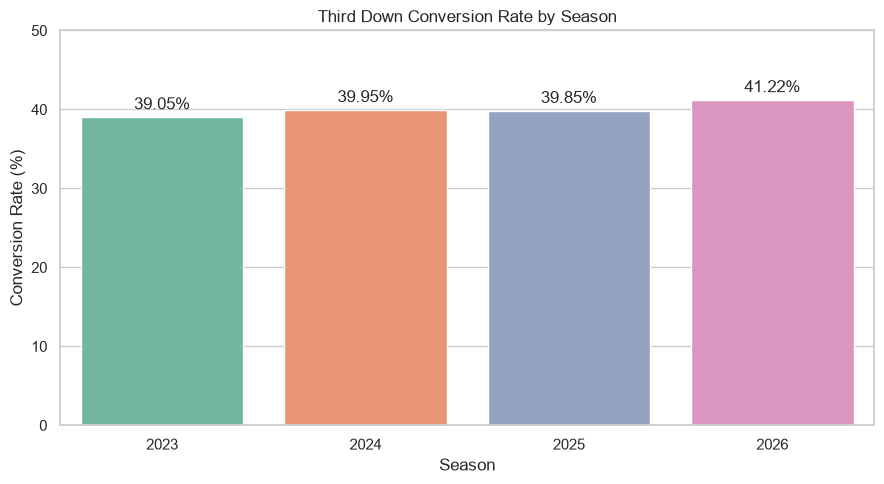

In [84]:
sns.set_theme(style="whitegrid")

season_plot = (third_down_plays.groupby("season", as_index=False)["third_down_converted"].mean())

season_plot["conversion_rate"] = season_plot["third_down_converted"] * 100

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=season_plot,
    x="season",
    y="conversion_rate",
    hue="season",
    palette="Set2",
    dodge=False,
    legend=False,
    ax=ax
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

ax.set_title("Third Down Conversion Rate by Season")
ax.set_xlabel("Season")
ax.set_ylabel("Conversion Rate (%)")
ax.set_ylim(0, 50)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

Third down conversion rates remained relatively consistent across the four seasons, ranging from 39.05% to 41.22%. The partial 2026 season had the highest conversion rate, but it contained fewer plays than the completed seasons. Therefore, comparisons with previous years should be interpreted cautiously.

### 6.3 Conversion Rate by Play Type

In [85]:
conversion_by_play_type = summarize_conversions(third_down_plays, "play_type")

conversion_by_play_type_display = conversion_by_play_type.rename(
    columns={
        "play_type": "Play Type",
        "number_of_plays": "Number of Plays",
        "successful_conversions": "Successful Conversions",
        "conversion_rate": "Conversion Rate (%)"
    }
).copy()

conversion_by_play_type_display['Play Type'] = (conversion_by_play_type_display['Play Type'].str.title())
conversion_by_play_type_display['Conversion Rate (%)'] = (conversion_by_play_type_display['Conversion Rate (%)'].map("{:.2f}%".format))

conversion_by_play_type_display.style.format({
    "Number of Plays": "{:,.0f}",
    "Successful Conversions": "{:,.0f}"
})

,Play Type,Number of Plays,Successful Conversions,Conversion Rate (%)
0,Pass,"16,455","5,782",35.14%
1,Run,"5,493","2,930",53.34%


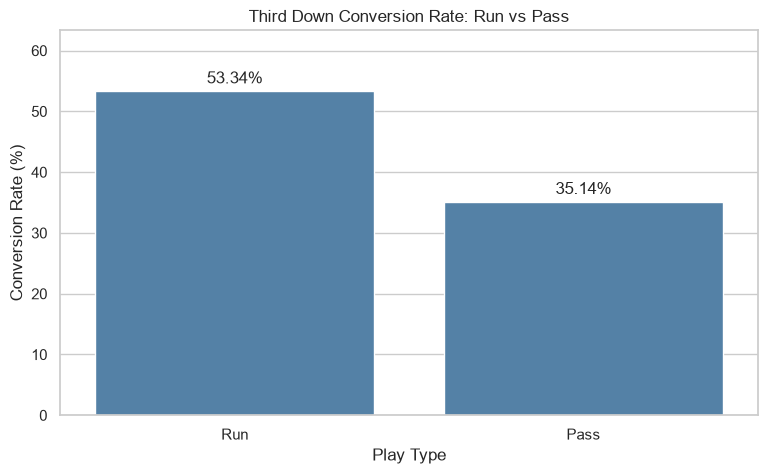

In [86]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=conversion_by_play_type,
    x = conversion_by_play_type["play_type"].str.title(),
    y = "conversion_rate",
    order = ["Run", "Pass"],
    color = "steelblue"
)

plt.title("Third Down Conversion Rate: Run vs Pass")
plt.xlabel("Play Type")
plt.ylabel("Conversion Rate (%)")
plt.ylim(0, conversion_by_play_type["conversion_rate"].max() + 10)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)
plt.show()

The data reveals that running plays had a higher third-down conversion rate than passing plays. Running plays were converted 53.34% of the time compared to 35.14% for passing plays. This doesn't mean that running caused a higher degree of conversions; teams may be more likely to run when fewer yards are needed for a first down.

### 6.4 Conversion Rate by Yards to Go

In [87]:
third_down_plays["yards_to_go_group"] = pd.cut(third_down_plays["ydstogo"], 
    bins=[0, 2, 5, 10, np.inf], 
    labels=[
        "1-2 Yards",
        "3-5 Yards",
        "6-10 Yards",
        "11+ Yards"
    ]
)

conversion_by_distance = summarize_conversions(third_down_plays, "yards_to_go_group")

conversion_by_distance_display = conversion_by_distance.rename(
    columns={
        "yards_to_go_group": "Yards to Go",
        "number_of_plays": "Number of Plays",
        "successful_conversions": "Successful Conversions",
        "conversion_rate": "Conversion Rate (%)"
    }
)

# Display successful conversion counts as whole numbers
conversion_by_distance_display["Successful Conversions"] = (
    conversion_by_distance_display["Successful Conversions"].astype(int)
)
conversion_by_distance_display['Conversion Rate (%)'] = (conversion_by_distance_display['Conversion Rate (%)'].map("{:.2f}%".format))


conversion_by_distance_display.style.format({
    "Number of Plays": "{:,.0f}",
    "Successful Conversions": "{:,.0f}"
})

,Yards to Go,Number of Plays,Successful Conversions,Conversion Rate (%)
0,1-2 Yards,"4,498","2,851",63.38%
1,3-5 Yards,"5,497","2,595",47.21%
2,6-10 Yards,"7,866","2,650",33.69%
3,11+ Yards,"4,087",616,15.07%


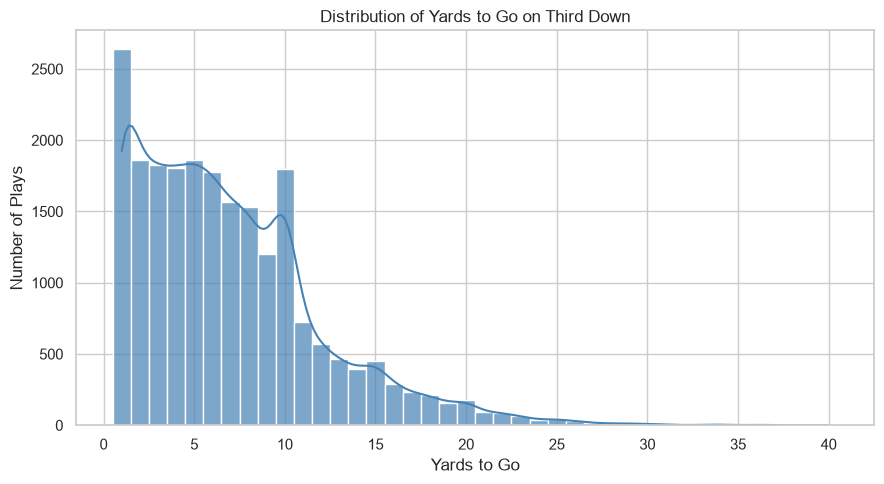

In [88]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=third_down_plays,
    x="ydstogo",
    discrete=True,
    kde=True,
    color="steelblue",
    alpha=0.7
)

plt.title("Distribution of Yards to Go on Third Down")
plt.xlabel("Yards to Go")
plt.ylabel("Number of Plays")
plt.tight_layout()
plt.show()

This histogram shows the distribution of yards to go on third downs. Each bar represents the number of plays at a particular distance. The histogram illustrates that majority of third down plays were 10 yards or less.

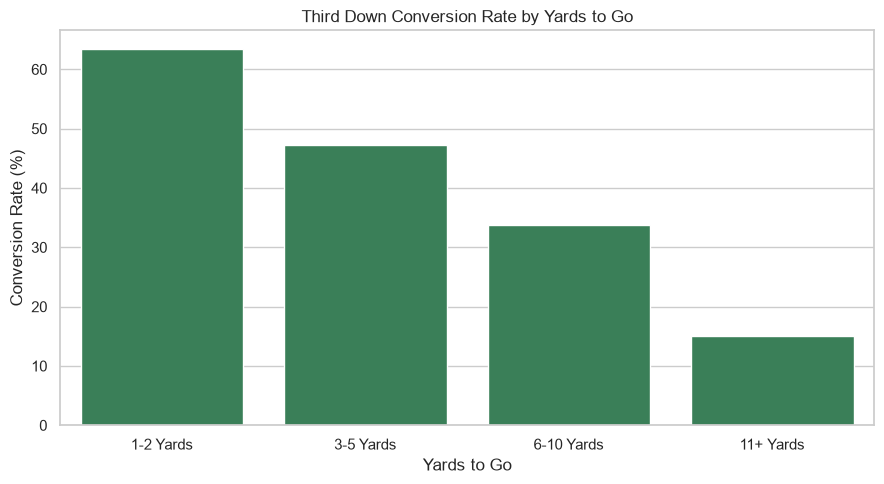

In [89]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data = conversion_by_distance,
    x = conversion_by_distance["yards_to_go_group"].str.title(),
    y = "conversion_rate",
    color = "seagreen"
)

plt.title("Third Down Conversion Rate by Yards to Go")
plt.xlabel("Yards to Go")
plt.ylabel("Conversion Rate (%)")
plt.tight_layout()
plt.show()

As the distance for a first down increased, the successful conversion rate decreased. Plays needing 1–2 yards for a first down were converted 63.38% of the time. However, plays needing 11+ yards only converted 15.07% of the time. This suggests that yards to go has a strong relationship with successful third down conversions.

### 6.5 Distance and Play Type

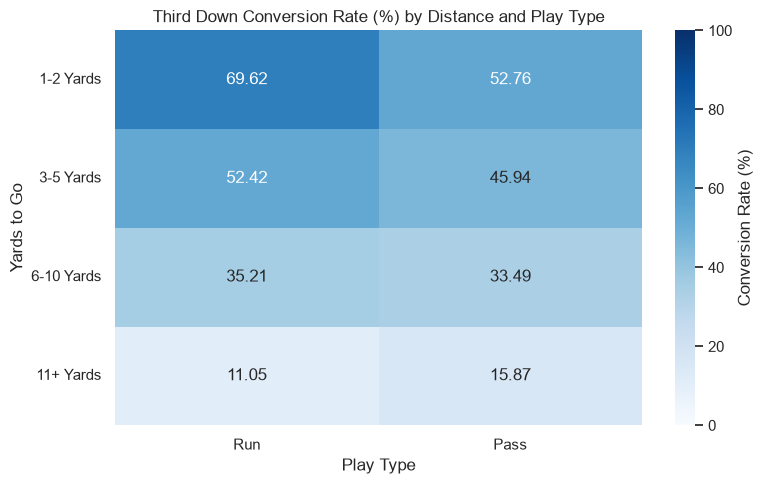

In [90]:
conversion_heatmap = third_down_plays.pivot_table(
    values="third_down_converted",
    index="yards_to_go_group",
    columns="play_type",
    aggfunc="mean",
    observed=False
) * 100

conversion_heatmap = conversion_heatmap.reindex(columns=["run", "pass"])
conversion_heatmap = conversion_heatmap.rename(columns={"run": "Run", "pass": "Pass"})

plt.figure(figsize=(8, 5))
sns.heatmap(
    conversion_heatmap,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Conversion Rate (%)"}
)

plt.title("Third Down Conversion Rate (%) by Distance and Play Type")
plt.xlabel("Play Type")
plt.ylabel("Yards to Go")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


This heatmap compares run and pass conversion rates within the same yards to go categories. It shows how teams were more successful at converting third downs with running plays when the yards to go were 5 and under. When first downs required 11+ yards, teams were more successful with passing plays.

### 6.6 Conversion Rate by Quarter

In [91]:
conversion_by_quarter = summarize_conversions(third_down_plays, "qtr")

conversion_by_quarter_display = conversion_by_quarter.rename(
    columns={
        "qtr": "Quarter",
        "number_of_plays": "Number of Plays",
        "successful_conversions": "Successful Conversions",
        "conversion_rate": "Conversion Rate (%)"
    }
)

# Display successful conversion counts as whole numbers
conversion_by_quarter_display["Successful Conversions"] = (
    conversion_by_quarter_display["Successful Conversions"].astype(int)
)

# Display quarters as whole numbers
conversion_by_quarter_display["Quarter"] = (
    conversion_by_quarter_display["Quarter"].astype(int)
)

# Display conversion rate with a percentage sign
conversion_by_quarter_display['Conversion Rate (%)'] = (conversion_by_quarter_display['Conversion Rate (%)'].map("{:.2f}%".format))

# Display quarter 5 as Overtime
conversion_by_quarter_display["Quarter"] = (
    conversion_by_quarter_display["Quarter"].replace({
        1: "1st",
        2: "2nd",
        3: "3rd",
        4: "4th",
        5: "Overtime"
        })
)

conversion_by_quarter_display.style.format({
    "Number of Plays": "{:,.0f}",
    "Successful Conversions": "{:,.0f}"
})

,Quarter,Number of Plays,Successful Conversions,Conversion Rate (%)
0,1st,"4,890","2,027",41.45%
1,2nd,"6,054","2,403",39.69%
2,3rd,"4,797","1,925",40.13%
3,4th,"6,101","2,314",37.93%
4,Overtime,106,43,40.57%


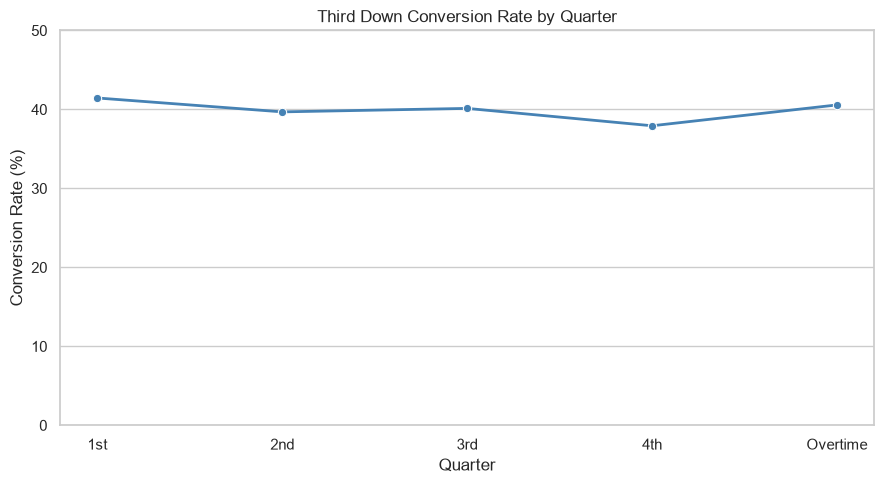

In [92]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.lineplot(
    data=conversion_by_quarter,
    x="qtr",
    y="conversion_rate",
    marker="o",
    linewidth=2,
    color="steelblue",
    sort=False,
    ax=ax
)


ax.set_title("Third Down Conversion Rate by Quarter")
ax.set_xlabel("Quarter")
ax.set_xticks(
    [1, 2, 3, 4, 5],
    labels=["1st", "2nd", "3rd", "4th", "Overtime"]
)
ax.set_ylabel("Conversion Rate (%)")
ax.set_ylim(0, 50)
ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

Conversion rates were relatively similar across the four regulation quarters. The first quarter had the highest conversion rate at 41.45%, compared with 37.93% in the fourth quarter. Overtime had a conversion rate of 40.57%, but contained only 106 plays.

### 6.7 Conversion Rate by Field Position

In [93]:
third_down_plays["field_position_group"] = pd.cut(
    third_down_plays["yardline_100"],
    bins=[0, 20, 50, 79, 100],
    labels=[
        "Opponent 1-20",
        "Opponent 21-50",
        "Own 21-50",
        "Own 1-20"
    ],
    include_lowest=True
)

conversion_by_field_position = summarize_conversions(third_down_plays, "field_position_group")

conversion_by_field_position_display = conversion_by_field_position.rename(
    columns={
        "field_position_group": "Field Position",
        "number_of_plays": "Number of Plays",
        "successful_conversions": "Successful Conversions",
        "conversion_rate": "Conversion Rate (%)"
    }
)

conversion_by_field_position_display['Conversion Rate (%)'] = (conversion_by_field_position_display['Conversion Rate (%)'].map("{:.2f}%".format))

conversion_by_field_position_display.style.format({
    "Number of Plays": "{:,.0f}",
    "Successful Conversions": "{:,.0f}"
})

,Field Position,Number of Plays,Successful Conversions,Conversion Rate (%)
0,Opponent 1-20,"3,678","1,470",39.97%
1,Opponent 21-50,"7,006","2,884",41.16%
2,Own 21-50,"9,431","3,791",40.20%
3,Own 1-20,"1,833",567,30.93%


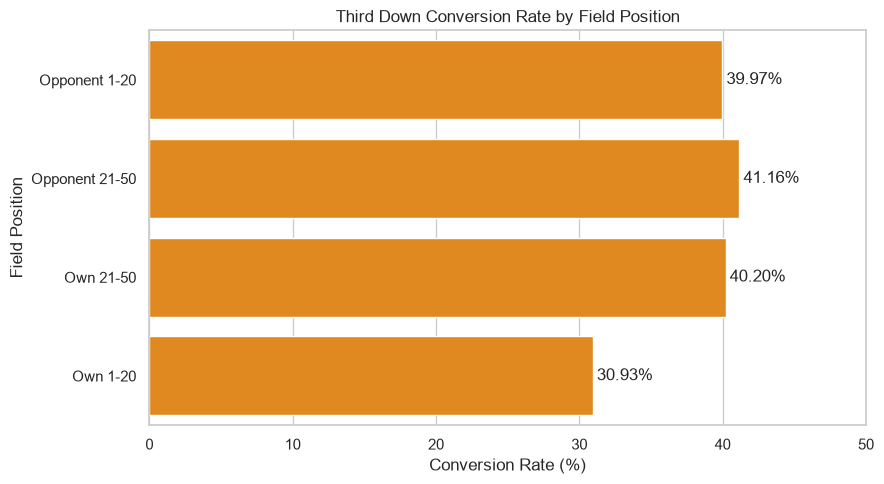

In [94]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=conversion_by_field_position,
    y="field_position_group",
    x="conversion_rate",
    color="darkorange",
    ax=ax
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=3
    )

ax.set_title("Third Down Conversion Rate by Field Position")
ax.set_xlabel("Conversion Rate (%)")
ax.set_ylabel("Field Position")
ax.set_xlim(0, 50)
ax.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

Conversion rates were highest between the opponent's 21–50 yard lines (41.16%) and lowest between the offense's own 1–20 yard lines (30.93%).

### 6.8 Conversion Rate by Score Situation

In [95]:
third_down_plays["score_situation"] = pd.cut(
    third_down_plays["score_differential"],
    bins = [-np.inf, -9, -1, 0, 8, np.inf],
    labels = [
        "Trailing by 9+",
        "Trailing by 1-8",
        "Tied",
        "Leading by 1-8",
        "Leading by 9+"
    ]
)

conversion_by_score = summarize_conversions(third_down_plays, "score_situation")

conversion_by_score_display = conversion_by_score.rename(
    columns={
        "score_situation": "Score Situation",
        "number_of_plays": "Number of Plays",
        "successful_conversions": "Successful Conversions",
        "conversion_rate": "Conversion Rate (%)"
    }
)

conversion_by_score_display['Conversion Rate (%)'] = (conversion_by_score_display['Conversion Rate (%)'].map("{:.2f}%".format))

conversion_by_score_display.style.format({
    "Number of Plays": "{:,.0f}",
    "Successful Conversions": "{:,.0f}"
})

,Score Situation,Number of Plays,Successful Conversions,Conversion Rate (%)
0,Trailing by 9+,"4,228","1,622",38.36%
1,Trailing by 1-8,"5,919","2,346",39.64%
2,Tied,"4,333","1,782",41.13%
3,Leading by 1-8,"4,571","1,795",39.27%
4,Leading by 9+,"2,897","1,167",40.28%


The conversion rate is pretty consistent across the five score situations. The rates ranged from 38.36% when a team is trailing by 9+ to 41.13% when the game is tied. This suggests that score differential by itself may not predict whether a team would successfully convert on third down.